In [2]:
import eurostat
import pandas as pd
import matplotlib.pyplot as plt

      Budżet państwa  Cały sektor (ESA)
2022            12.4            104.475
2023            85.6            177.442
2024           210.9            236.562
2025           275.6            283.615


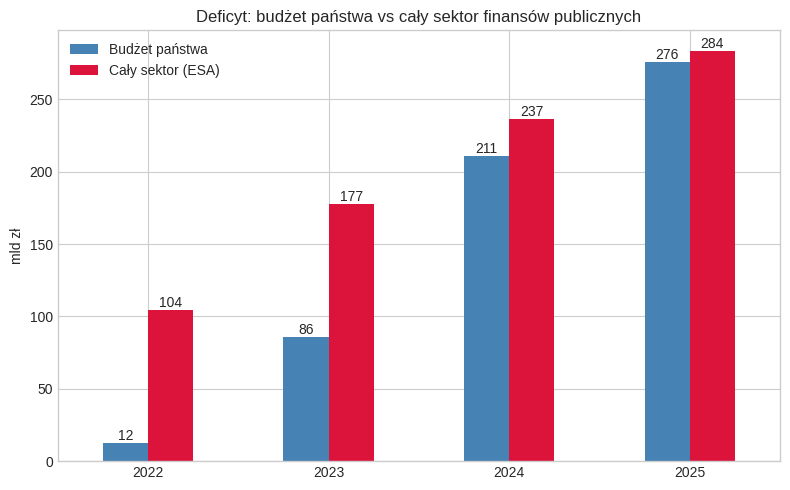

In [4]:
raw = eurostat.get_data_df("gov_10dd_edpt1",
        filter_pars={"geo": ["PL"], "unit": "MIO_NAC", "sector": "S13", "na_item": "B9"})
lata = [c for c in raw.columns if str(c).isdigit()]
sektor = raw[lata].iloc[0].astype(float).abs() / 1000
sektor.index = sektor.index.astype(int)

budzet = pd.Series({2022: 12.4,    
                    2023: 85.6,    
                    2024: 210.9,
                    2025: 275.6})

lat = [2022, 2023, 2024, 2025]
df = pd.DataFrame({"Budżet państwa": budzet.loc[lat],
                   "Cały sektor (ESA)": sektor.loc[lat]})
print(df)

plt.style.use("seaborn-v0_8-whitegrid")
ax = df.plot(kind="bar", figsize=(8, 5), color=["steelblue", "crimson"])
ax.set_ylabel("mld zł")
ax.set_title("Deficyt: budżet państwa vs cały sektor finansów publicznych")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f")
plt.tight_layout()
plt.savefig("img/deficyt_państwo_vs_caly_sektor.png", bbox_inches="tight")
plt.show()

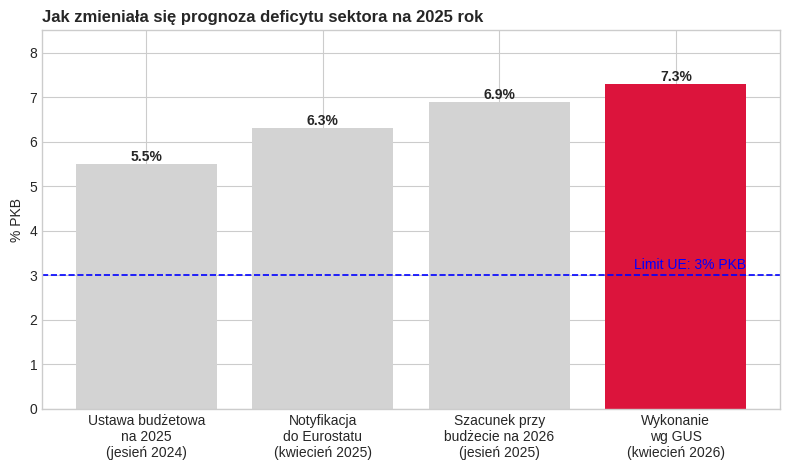

In [ ]:
dane = pd.DataFrame({
    "etap": [
        "Ustawa budżetowa\nna 2025\n(jesień 2024)",
        "Notyfikacja\ndo Eurostatu\n(kwiecień 2025)",
        "Szacunek przy\nbudżecie na 2026\n(jesień 2025)",
        "Wykonanie\nwg GUS\n(kwiecień 2026)",
    ],
    "deficyt": [5.5, 6.3, 6.9, 7.3],
})

kolory = ["lightgray"] * (len(dane) - 1) + ["crimson"]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.8))
slupki = ax.bar(dane["etap"], dane["deficyt"], color=kolory)
ax.bar_label(slupki, fmt="%.1f%%", fontweight="bold")

ax.axhline(3, color="blue", linestyle="--", linewidth=1.2)
ax.text(len(dane) - 0.6, 3.15, "Limit UE: 3% PKB", color="blue", ha="right")

ax.set_ylabel("% PKB")
ax.set_ylim(0, 8.5)
ax.set_title("Jak zmieniała się prognoza deficytu sektora na 2025 rok",
             loc="left", fontweight="bold")

plt.tight_layout()
plt.savefig("img/deficyt_prognoza_vs_wykonanie_2025.png", dpi=180, bbox_inches="tight")
plt.show()